In [29]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False


import pandas as pd
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor 
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression
from sklearn.preprocessing import PolynomialFeatures,StandardScaler,OneHotEncoder
from sklearn.metrics import mean_absolute_error # 평균절대값오차 오차범위
from sklearn.model_selection import train_test_split
from scipy.special import expit, softmax # expit:이진분류함수, softmax:다중분류 함수 0-1숫자로 변환
import numpy as np
from io import StringIO

In [30]:
# LogisticRegression 이진분류 -> 다중분류
fish = pd.read_csv('data/fish_logistic.csv')
fish.head(2)

,Species,Weight,Length,Diagonal,Height,Width
0,Bream,242.0,25.4,30.0,11.52,4.0200
1,Bream,290.0,26.3,31.2,12.48,4.3056


In [31]:
fish['Species'].unique() # ['Bream', 'Roach', 'Whitefish', 'Parkki', 'Perch', 'Pike', 'Smelt'] 7종류


<StringArray>
['Bream', 'Roach', 'Whitefish', 'Parkki', 'Perch', 'Pike', 'Smelt']
Length: 7, dtype: str

In [32]:
# 데이터 전처리
data = fish[fish.columns[1:]].values
label = fish['Species'].values
data,label

(array([[2.42000e+02, 2.54000e+01, 3.00000e+01, 1.15200e+01, 4.02000e+00],
        [2.90000e+02, 2.63000e+01, 3.12000e+01, 1.24800e+01, 4.30560e+00],
        [3.40000e+02, 2.65000e+01, 3.11000e+01, 1.23778e+01, 4.69610e+00],
        [3.63000e+02, 2.90000e+01, 3.35000e+01, 1.27300e+01, 4.45550e+00],
        [4.30000e+02, 2.90000e+01, 3.40000e+01, 1.24440e+01, 5.13400e+00],
        [4.50000e+02, 2.97000e+01, 3.47000e+01, 1.36024e+01, 4.92740e+00],
        [5.00000e+02, 2.97000e+01, 3.45000e+01, 1.41795e+01, 5.27850e+00],
        [3.90000e+02, 3.00000e+01, 3.50000e+01, 1.26700e+01, 4.69000e+00],
        [4.50000e+02, 3.00000e+01, 3.51000e+01, 1.40049e+01, 4.84380e+00],
        [5.00000e+02, 3.07000e+01, 3.62000e+01, 1.42266e+01, 4.95940e+00],
        [4.75000e+02, 3.10000e+01, 3.62000e+01, 1.42628e+01, 5.10420e+00],
        [5.00000e+02, 3.10000e+01, 3.62000e+01, 1.43714e+01, 4.81460e+00],
        [5.00000e+02, 3.15000e+01, 3.64000e+01, 1.37592e+01, 4.36800e+00],
        [3.40000e+02, 3.2

In [33]:
# 데이터 분리
train_data,test_data,train_label,test_label = train_test_split(data,label,random_state=42)


In [71]:
# LogisticRegression - 정규화작업 필수

ss= StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data)

In [ ]:
# 다중분류
# C(대문자 표기) - alpha,C 규제 : 높아질수록 완화, 낮아질수록 강화
# alpha for문 그래프로 가장 최적화된 규제를  찾아서 적용
# max_iter 반복을 자동화해주는 매개변수 최적의 방안을 찾을때까지 반복됨

lr = LogisticRegression(C=20,max_iter=1000) # 디폴트가 20 # 큰 규모일땐 사용이 어려움
lr.fit(train_scaled,train_label)


,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",20
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in

In [53]:
lr.classes_

array(['Bream', 'Parkki', 'Perch', 'Pike', 'Roach', 'Smelt', 'Whitefish'],
      dtype=object)

In [54]:
lr.predict_proba(test_scaled[:5])
decisions = lr.decision_function(test_scaled[:5]) 
soft = softmax(decisions,axis=1) # axis = 행방향
np.round(soft,decimals=3)

array([[0.   , 0.014, 0.842, 0.   , 0.135, 0.007, 0.003],
       [0.   , 0.003, 0.044, 0.   , 0.007, 0.946, 0.   ],
       [0.   , 0.   , 0.034, 0.934, 0.015, 0.016, 0.   ],
       [0.011, 0.034, 0.305, 0.006, 0.567, 0.   , 0.076],
       [0.   , 0.   , 0.904, 0.002, 0.089, 0.002, 0.001]])

In [ ]:

# Species	Weight	Length	Diagonal	Height	Width
# 242.0,25.4,30.0,11.52,4.0200
# 290.0,26.3,31.2,12.48,4.3056

# 무게 길이 대각선 높이 넓이를 입력받아 생선을 분류확률을 출력하시오
# 분류생선과 확률을 출력
# 분류생선 :93.1%의 확률로 Bream 판별됩니다.



In [70]:
# in_data = '242.0,25.4,30.0,11.52,4.0200'
# in_data = '55,14.7,16.5,6.8475,2.3265'
# in_data = '32,13.7,14.7,3.528,1.9992'
# in_data = '300,35,38.8,5.9364,4.3844'?
in_data = input('데이터입력:')
in_data = list(map(float,in_data.split(',')))
in_data = ss.transform([in_data])
# total_data = []
# total_data.append(in_data)

result=lr.predict(in_data)

in_data = lr.decision_function(in_data)
in_data = softmax(in_data,axis=1)
result2=np.round(in_data,decimals=3)
result2=result2.max()
print(f'분류생선: {result2*100}%확률로 {result[0]}판별됩니다')
result


분류생선: 92.0%확률로 Pike판별됩니다


array(['Pike'], dtype=object)

In [1]:
# 다중분류
# C(대문자 표기) - alpha,C 규제 : 높아질수록 완화, 낮아질수록 강화
# alpha for문 그래프로 가장 최적화된 규제를  찾아서 적용
# max_iter 반복을 자동화해주는 매개변수 최적의 방안을 찾을때까지 반복됨
train_score = []
test_score = []
cc = [0.001,0.01,0.1,1,10,20,50,100]

for c in cc:
    lr = LogisticRegression(C=c,max_iter=1000) # 디폴트가 20 # 큰 규모일땐 사용이 어려움
    lr.fit(train_scaled,train_label)
    train_score.append(lr.score(train_scaled,train_label))    
    test_score.append(lr.score(test_scaled,test_label))    
    print()


NameError: name 'LogisticRegression' is not defined

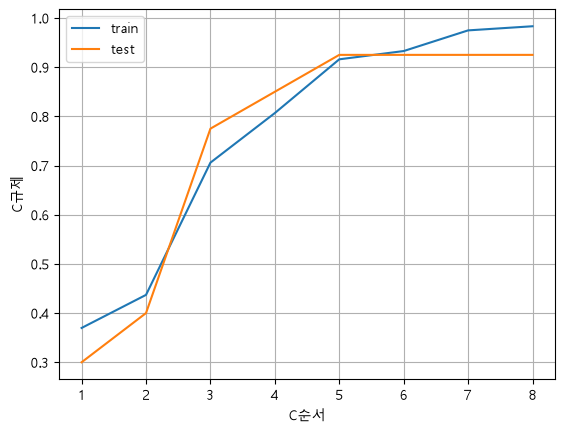

In [82]:
# C의 규제 선그래프
list1 = [1,2,3,4,5,6,7,8]
plt.plot(list1,train_score)
plt.plot(list1,test_score)
plt.xlabel('C순서')
plt.ylabel('C규제')
plt.legend(['train','test'])
plt.grid()
plt.show()